# Lezione 07 — Notebook Docente TakeHome

## Pricing Monte Carlo di una call asiatica sull'EURO STOXX 50 con tasso di interesse stocastico

**Data di riferimento:** 27 luglio 2026

Il notebook sviluppa il Caso TakeHome della Lezione 7 secondo la Scheda Costruzione e la Scheda Caso aggiornate.

Il problema è formulato direttamente sotto la misura risk-neutral \(\mathbb Q\). Il sottostante segue una **diffusione geometrica con drift stocastico**, perché il drift dipende dal tasso corto \(r_t\); il tasso nominale segue un processo CIR.

L'obiettivo è stimare

\[
\widehat V_M
=
\frac{1}{M}\sum_{k=1}^M V^{(k)},
\qquad
V^{(k)}
=
\widehat D^{(k)}(0,T)\,H_T^{(k)},
\]

dove

\[
H_T^{(k)}
=
\max\!\left(A_T^{(k)}-K,0\right),
\qquad
A_T^{(k)}
=
\frac{1}{12}\sum_{h=1}^{12}S_{\tau_h}^{(k)}.
\]

La singola simulazione è denominata **replica Monte Carlo** ed è indicata con \(k\). Il termine *scenario* non viene utilizzato come sinonimo di replica.

# Flusso logico-teorico risolutivo

| Passo | Finalità risolutiva | Formula teorico-matematica / definizione / proprietà / teorema | Applicazione nel caso | Output o controllo collegato |
|---:|---|---|---|---|
| 1 | Fissare misura di pricing e fattori di rischio | dinamiche assegnate sotto \(\mathbb Q\) | diffusione geometrica di \(S_t\) con drift stocastico e CIR per \(r_t\) | coerenza del modello e dei parametri |
| 2 | Costruire la dipendenza e simulare i fattori | \(dW_t^{(S)}dW_t^{(r)}=\rho\,dt\); discretizzazioni assegnate | shock gaussiani correlati e matrici \(M\times(N+1)\) | correlazione empirica, positività di \(S_t\), valori CIR negativi |
| 3 | Costruire la quantità path-dependent | \(\tau_h=h/12\), \(A_T^{(k)}=\frac1{12}\sum_h S_{\tau_h}^{(k)}\) | selezione dei dodici fixing e media asiatica | controllo min–media–max |
| 4 | Determinare esercizio e payoff | \(H_T^{(k)}=(A_T^{(k)}-K)^+\) | esercizio se \(A_T^{(k)}>K\) | \(\widehat{\mathbb Q}(A_T>K)\), non-negatività del payoff |
| 5 | Attualizzare replica per replica | \(\widehat D^{(k)}(0,T)=\exp[-\sum_j r_{t_j}^{(k)}\Delta t]\) | somma di Riemann sinistra sulla traiettoria del tasso della stessa replica | positività del fattore di sconto |
| 6 | Costruire il valore e il prezzo Monte Carlo | \(V^{(k)}=\widehat D^{(k)}H_T^{(k)}\), \(\widehat V_M=M^{-1}\sum_kV^{(k)}\) | aggregazione dei valori attualizzati | prezzo, SE, IC 95% |
| 7 | Valutare precisione statistica e discretizzazione | \(SE=s_V/\sqrt M\); confronto fra griglie | \(M=1\,000,5\,000,10\,000,50\,000\) e griglia più fine con fixing invariati | convergenza Monte Carlo e stabilità numerica |
| 8 | Interpretare il risultato e delimitarne la portata | distinzione tra valore di modello, errore Monte Carlo, discretizzazione ed errore di modello | lettura finanziaria degli output | interpretazione conclusiva, limiti e riproducibilità |

# Scomposizione in sei tappe

1. **Tappa 1 — Setup, griglia, fixing e shock:** parametri, classificazione, griglia temporale, date di fixing e shock correlati.
2. **Tappa 2 — Simulazione dei fattori:** traiettorie di \(r_t\) e \(S_t\) con la convenzione CIR vincolante.
3. **Tappa 3 — Media asiatica ed esercizio:** estrazione dei fixing, costruzione di \(A_T\) e stima di \(\mathbb Q(A_T>K)\).
4. **Tappa 4 — Payoff e attualizzazione:** costruzione di \(H_T\), integrale del tasso e fattore di sconto replica per replica.
5. **Tappa 5 — Pricing e sintesi numerica:** \(V^{(k)}\), prezzo, SE, IC 95% e tabelle di sintesi.
6. **Tappa 6 — Diagnostica, griglia, grafici e chiusura:** convergenza Monte Carlo, confronto con griglia più fine, controlli finali, grafici e interpretazione.

Le sei tappe appartengono allo sviluppo ordinario del notebook. Un eventuale Regime C non costituisce una fase obbligatoria.

# Tappa 1 — Setup, griglia, fixing e shock

**Input.** Specifiche del caso e seed pseudo-casuale.

**Operazione.** Si costruiscono parametri, griglia, fixing mensili e shock gaussiani correlati.

**Output.** Tabella dei parametri e correlazione empirica degli shock.

**Controllo.** La correlazione empirica deve essere coerente con \(\rho=-0.25\).

**Passaggio successivo.** Gli shock alimentano congiuntamente le traiettorie di \(S_t\) e \(r_t\).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

SEED = 12345
rng = np.random.default_rng(SEED)

# Parametri assegnati
S0 = 6286.35
K = 6300.0
T = 1.0
q = 0.025
sigma_S = 0.18

r0 = 0.02185
kappa_r = 1.25
theta_r = 0.0220
sigma_r = 0.040
rho = -0.25

N = 252
dt = T / N
M = 50_000
n_fix = 12

fixing_indices = np.arange(N // n_fix, N + 1, N // n_fix)
time_grid = np.linspace(0.0, T, N + 1)

# Tabella 1
df_parametri = pd.DataFrame([
    ["Data", "t_0", "27/07/2026", "data di riferimento"],
    ["Sottostante", "S_0", S0, "dato osservato"],
    ["Contratto", "K", K, "specifica contrattuale"],
    ["Contratto", "T", T, "specifica contrattuale"],
    ["Contratto", "fixing", n_fix, "specifica contrattuale"],
    ["Dividendi", "q", q, "proxy di mercato arrotondata"],
    ["Sottostante", "sigma_S", sigma_S, "proxy market-consistent"],
    ["Tasso CIR", "r_0", r0, "dato osservato"],
    ["Tasso CIR", "kappa_r", kappa_r, "parametro didattico"],
    ["Tasso CIR", "theta_r", theta_r, "parametro didattico"],
    ["Tasso CIR", "sigma_r", sigma_r, "parametro didattico"],
    ["Dipendenza", "rho", rho, "ipotesi modellistica"],
    ["Simulazione", "N", N, "intervalli temporali"],
    ["Simulazione", "Delta t", dt, "griglia principale"],
    ["Simulazione", "M", M, "repliche Monte Carlo"],
    ["Simulazione", "seed", SEED, "seme pseudo-casuale"],
], columns=["Componente", "Parametro", "Valore", "Natura"])

display(Markdown("### Tabella 1 — Parametri del caso"))
display(df_parametri)

# Shock correlati
Z1 = rng.standard_normal((M, N))
Z2 = rng.standard_normal((M, N))
Z_S = Z1
Z_r = rho * Z1 + np.sqrt(1.0 - rho**2) * Z2
del Z2

corr_emp = np.corrcoef(Z_S.ravel(), Z_r.ravel())[0, 1]
feller_lhs = 2.0 * kappa_r * theta_r
feller_rhs = sigma_r**2

print(f"Condizione di Feller: {feller_lhs:.6f} > {feller_rhs:.6f} -> {feller_lhs > feller_rhs}")
print(f"Fixing: {fixing_indices.tolist()}")
print(f"Correlazione target: {rho:.4f}")
print(f"Correlazione empirica degli shock: {corr_emp:.4f}")

### Tabella 1 — Parametri del caso

,Componente,Parametro,Valore,Natura
0,Data,t_0,27/07/2026,data di riferimento
1,Sottostante,S_0,6286.35,dato osservato
2,Contratto,K,6300.0,specifica contrattuale
3,Contratto,T,1.0,specifica contrattuale
4,Contratto,fixing,12,specifica contrattuale
5,Dividendi,q,0.025,proxy di mercato arrotondata
6,Sottostante,sigma_S,0.18,proxy market-consistent
7,Tasso CIR,r_0,0.02185,dato osservato
8,Tasso CIR,kappa_r,1.25,parametro didattico
9,Tasso CIR,theta_r,0.022,parametro didattico


Condizione di Feller: 0.055000 > 0.001600 -> True
Fixing: [21, 42, 63, 84, 105, 126, 147, 168, 189, 210, 231, 252]
Correlazione target: -0.2500
Correlazione empirica degli shock: -0.2499


# Tappa 2 — Simulazione delle traiettorie di \(r_t\) e \(S_t\)

**Input.** Parametri, griglia e shock della Tappa 1.

**Operazione.** Il CIR è discretizzato con

\[
r_{t_{j+1}}^{(k)}
=
r_{t_j}^{(k)}
+
\kappa_r(\theta_r-r_{t_j}^{(k)})\Delta t
+
\sigma_r\sqrt{\max(r_{t_j}^{(k)},0)}\sqrt{\Delta t}\,Z_{r,j+1}^{(k)}.
\]

Il `max` agisce **solo nella radice quadrata**. Il nuovo valore del tasso non viene forzato a zero.

Per l'indice si usa

\[
S_{t_{j+1}}^{(k)}
=
S_{t_j}^{(k)}
\exp\!\left[
\left(r_{t_j}^{(k)}-q-\frac12\sigma_S^2\right)\Delta t
+
\sigma_S\sqrt{\Delta t}\,Z_{S,j+1}^{(k)}
\right].
\]

**Output.** Matrici delle traiettorie e valori terminali.

**Controlli.** \(S_t>0\); eventuali valori CIR negativi sono rilevati e mantenuti.

**Passaggio successivo.** Dalle traiettorie di \(S_t\) vengono selezionati i dodici fixing contrattuali.

In [2]:
r_paths = np.empty((M, N + 1), dtype=float)
S_paths = np.empty((M, N + 1), dtype=float)
r_paths[:, 0] = r0
S_paths[:, 0] = S0

for j in range(N):
    r_j = r_paths[:, j]
    r_paths[:, j + 1] = (
        r_j
        + kappa_r * (theta_r - r_j) * dt
        + sigma_r * np.sqrt(np.maximum(r_j, 0.0)) * np.sqrt(dt) * Z_r[:, j]
    )
    S_paths[:, j + 1] = S_paths[:, j] * np.exp(
        (r_j - q - 0.5 * sigma_S**2) * dt
        + sigma_S * np.sqrt(dt) * Z_S[:, j]
    )

S_T = S_paths[:, -1]
r_T = r_paths[:, -1]

min_S = float(np.min(S_paths))
n_neg_r = int(np.sum(r_paths < 0.0))
min_r = float(np.min(r_paths))

print(f"Minimo S_t simulato: {min_S:.6f}")
print(f"Numero di valori CIR negativi da discretizzazione: {n_neg_r}")
print(f"Minimo r_t simulato: {min_r:.8f}")

Minimo S_t simulato: 2719.883695
Numero di valori CIR negativi da discretizzazione: 0
Minimo r_t simulato: 0.00915677


# Tappa 3 — Fixing, media asiatica e probabilità risk-neutral di esercizio

**Input.** Traiettorie simulate dell'indice.

**Operazione.** Si estraggono esclusivamente i dodici fixing mensili:

\[
21,42,\ldots,252.
\]

Per ogni replica,

\[
A_T^{(k)}
=
\frac1{12}\sum_{h=1}^{12}S_{\tau_h}^{(k)}.
\]

La frequenza campionaria

\[
\widehat{\mathbb Q}(A_T>K)
=
\frac1M\sum_{k=1}^M
\mathbf 1_{\{A_T^{(k)}>K\}}
\]

stima la probabilità dell'evento \(A_T>K\) sotto la misura di pricing \(\mathbb Q\), non una probabilità fisica di mercato.

**Output.** \(A_T\) e probabilità simulata di esercizio.

**Controllo.** Per ogni replica la media deve essere compresa tra minimo e massimo dei dodici fixing.

**Passaggio successivo.** \(A_T\) determina il payoff della call asiatica.

In [3]:
S_fixings = S_paths[:, fixing_indices]
A_T = np.mean(S_fixings, axis=1)

min_fix = np.min(S_fixings, axis=1)
max_fix = np.max(S_fixings, axis=1)
media_bounds_ok = bool(np.all((A_T >= min_fix) & (A_T <= max_fix)))

exercise = A_T > K
prob_exercise_Q = float(np.mean(exercise))

print(f"Controllo min <= A_T <= max sui fixing: {media_bounds_ok}")
print(f"Stima Monte Carlo Q(A_T > K): {prob_exercise_Q:.4%}")

Controllo min <= A_T <= max sui fixing: True
Stima Monte Carlo Q(A_T > K): 45.8820%


# Tappa 4 — Payoff e attualizzazione replica per replica

**Input.** Media asiatica e traiettorie del tasso.

**Operazione.** Il payoff è

\[
H_T^{(k)}
=
\max(A_T^{(k)}-K,0).
\]

L'integrale del tasso è approssimato mediante somma di Riemann sinistra:

\[
\int_0^T r_u^{(k)}du
\approx
\sum_{j=0}^{N-1}r_{t_j}^{(k)}\Delta t,
\]

e quindi

\[
\widehat D^{(k)}(0,T)
=
\exp\!\left(
-\sum_{j=0}^{N-1}r_{t_j}^{(k)}\Delta t
\right).
\]

**Output.** \(H_T^{(k)}\) e \(\widehat D^{(k)}(0,T)\).

**Controlli.** Payoff non negativo e nullo quando \(A_T\le K\); fattore di sconto positivo.

**Passaggio successivo.** Payoff e fattore di sconto vengono combinati nella stessa replica.

In [4]:
H_T = np.maximum(A_T - K, 0.0)
integral_r = np.sum(r_paths[:, :-1], axis=1) * dt
D_T = np.exp(-integral_r)

payoff_nonneg_ok = bool(np.all(H_T >= 0.0))
payoff_zero_ok = bool(np.all(H_T[~exercise] == 0.0))
discount_positive_ok = bool(np.all(D_T > 0.0))

print(f"Payoff non negativo: {payoff_nonneg_ok}")
print(f"Payoff nullo se A_T <= K: {payoff_zero_ok}")
print(f"Fattore di sconto positivo: {discount_positive_ok}")

Payoff non negativo: True
Payoff nullo se A_T <= K: True
Fattore di sconto positivo: True


# Tappa 5 — Valore attualizzato, prezzo Monte Carlo e sintesi numerica

**Input.** Payoff e fattore di sconto.

**Operazione.**

\[
V^{(k)}
=
\widehat D^{(k)}(0,T)H_T^{(k)},
\]

\[
\widehat V_M
=
\frac1M\sum_{k=1}^M V^{(k)},
\qquad
SE(\widehat V_M)
=
\frac{s_V}{\sqrt M}.
\]

L'intervallo di confidenza Monte Carlo approssimato al \(95\%\) è

\[
\widehat V_M
\pm
1.96\,SE(\widehat V_M).
\]

**Output.** Tabelle delle statistiche dei fattori e del pricing.

**Controllo.** Deve valere replica per replica \(V^{(k)}=\widehat D^{(k)}H_T^{(k)}\).

**Passaggio successivo.** Si studiano convergenza Monte Carlo, discretizzazione e rappresentazioni grafiche.

In [5]:
V = D_T * H_T
price = float(np.mean(V))
s_V = float(np.std(V, ddof=1))
SE = s_V / np.sqrt(M)
CI_low = price - 1.96 * SE
CI_high = price + 1.96 * SE

identity_ok = bool(np.allclose(V, D_T * H_T))

df_stats = pd.DataFrame({
    "Variabile": ["S_T", "r_T", "A_T"],
    "Media": [np.mean(S_T), np.mean(r_T), np.mean(A_T)],
    "Deviazione standard": [np.std(S_T, ddof=1), np.std(r_T, ddof=1), np.std(A_T, ddof=1)]
})

df_pricing = pd.DataFrame({
    "Metrica": [
        "Probabilità risk-neutral simulata Q(A_T > K)",
        "Payoff medio non attualizzato",
        "Prezzo Monte Carlo",
        "Errore standard",
        "IC 95% - estremo inferiore",
        "IC 95% - estremo superiore",
    ],
    "Valore": [
        prob_exercise_Q,
        np.mean(H_T),
        price,
        SE,
        CI_low,
        CI_high,
    ]
})

display(Markdown("### Tabella 2 — Statistiche dei fattori e della media asiatica"))
display(df_stats)

display(Markdown("### Tabella 3 — Sintesi del payoff e del pricing"))
display(df_pricing)

print(f"Identità V = D * H replica per replica: {identity_ok}")

### Tabella 2 — Statistiche dei fattori e della media asiatica

,Variabile,Media,Deviazione standard
0,S_T,6260.002443,1137.118209
1,r_T,0.021972,0.003592
2,A_T,6273.181866,698.006018


### Tabella 3 — Sintesi del payoff e del pricing

,Metrica,Valore
0,Probabilità risk-neutral simulata Q(A_T > K),0.458820
1,Payoff medio non attualizzato,264.490916
2,Prezzo Monte Carlo,258.946449
3,Errore standard,1.879868
4,IC 95% - estremo inferiore,255.261907
5,IC 95% - estremo superiore,262.630990


Identità V = D * H replica per replica: True


# Tappa 6 — Diagnostica Monte Carlo, griglia, grafici e controlli finali

La tappa conclusiva separa due fonti di approssimazione:

- **errore Monte Carlo**, studiato variando \(M\);
- **errore di discretizzazione temporale**, studiato confrontando la griglia principale con una griglia più fine.

Il confronto fra griglie mantiene le dodici date di fixing e usa driver browniani accoppiati, in modo da rendere il confronto più informativo.

In [6]:
# Diagnostica Monte Carlo mediante prefissi della stessa simulazione
M_grid = [1_000, 5_000, 10_000, 50_000]
rows = []
for m in M_grid:
    v_m = V[:m]
    p_m = float(np.mean(v_m))
    se_m = float(np.std(v_m, ddof=1) / np.sqrt(m))
    rows.append([m, p_m, se_m, se_m * np.sqrt(m)])

df_mc = pd.DataFrame(rows, columns=["M", "Prezzo stimato", "SE", "SE * sqrt(M)"])

display(Markdown("### Tabella 4 — Diagnostica Monte Carlo"))
display(df_mc)

# Controllo dell'ordine SE ~ M^{-1/2}
se_scaled = df_mc["SE * sqrt(M)"].to_numpy()
se_scaling_cv = np.std(se_scaled, ddof=1) / np.mean(se_scaled)
se_scaling_ok = bool(se_scaling_cv < 0.10)

print(f"Coefficiente di variazione di SE*sqrt(M): {se_scaling_cv:.4f}")
print(f"Comportamento SE ~ M^(-1/2) coerente: {se_scaling_ok}")

### Tabella 4 — Diagnostica Monte Carlo

,M,Prezzo stimato,SE,SE * sqrt(M)
0,1000,270.734089,13.802204,436.464025
1,5000,275.807446,6.168678,436.191406
2,10000,269.196086,4.291394,429.139396
3,50000,258.946449,1.879868,420.351305


Coefficiente di variazione di SE*sqrt(M): 0.0176
Comportamento SE ~ M^(-1/2) coerente: True


In [7]:
# Confronto accoppiato fra N=252 e N=504 mantenendo 12 fixing.
# Per contenere costo e memoria del controllo di discretizzazione si usa M_refine=10.000.

def simulate_from_shocks(Z1, Z2, N_steps):
    M_sim = Z1.shape[0]
    dt_sim = T / N_steps
    ZS = Z1
    ZR = rho * Z1 + np.sqrt(1.0 - rho**2) * Z2

    r = np.empty((M_sim, N_steps + 1))
    S = np.empty((M_sim, N_steps + 1))
    r[:, 0] = r0
    S[:, 0] = S0

    for j in range(N_steps):
        r_j = r[:, j]
        r[:, j + 1] = (
            r_j
            + kappa_r * (theta_r - r_j) * dt_sim
            + sigma_r * np.sqrt(np.maximum(r_j, 0.0)) * np.sqrt(dt_sim) * ZR[:, j]
        )
        S[:, j + 1] = S[:, j] * np.exp(
            (r_j - q - 0.5 * sigma_S**2) * dt_sim
            + sigma_S * np.sqrt(dt_sim) * ZS[:, j]
        )

    fixing_step = N_steps // 12
    fixing_idx = np.arange(fixing_step, N_steps + 1, fixing_step)
    A = np.mean(S[:, fixing_idx], axis=1)
    H = np.maximum(A - K, 0.0)
    D = np.exp(-np.sum(r[:, :-1], axis=1) * dt_sim)
    Vsim = D * H
    return Vsim

M_refine = 10_000
rng_ref = np.random.default_rng(SEED + 1)

# Driver fini N=504
Z1_f = rng_ref.standard_normal((M_refine, 504))
Z2_f = rng_ref.standard_normal((M_refine, 504))

# Driver grossolani ottenuti aggregando due incrementi fini
Z1_c = (Z1_f[:, 0::2] + Z1_f[:, 1::2]) / np.sqrt(2.0)
Z2_c = (Z2_f[:, 0::2] + Z2_f[:, 1::2]) / np.sqrt(2.0)

V_coarse = simulate_from_shocks(Z1_c, Z2_c, 252)
V_fine = simulate_from_shocks(Z1_f, Z2_f, 504)

price_coarse = float(np.mean(V_coarse))
price_fine = float(np.mean(V_fine))
grid_diff = price_fine - price_coarse
paired_se = float(np.std(V_fine - V_coarse, ddof=1) / np.sqrt(M_refine))

df_grid = pd.DataFrame({
    "Griglia": ["N=252", "N=504", "Differenza fine - base"],
    "Prezzo": [price_coarse, price_fine, grid_diff]
})

display(Markdown("### Confronto di discretizzazione"))
display(df_grid)
print(f"SE della differenza accoppiata: {paired_se:.6f}")

### Confronto di discretizzazione

,Griglia,Prezzo
0,N=252,259.708578
1,N=504,259.707666
2,Differenza fine - base,-0.000911


SE della differenza accoppiata: 0.000212


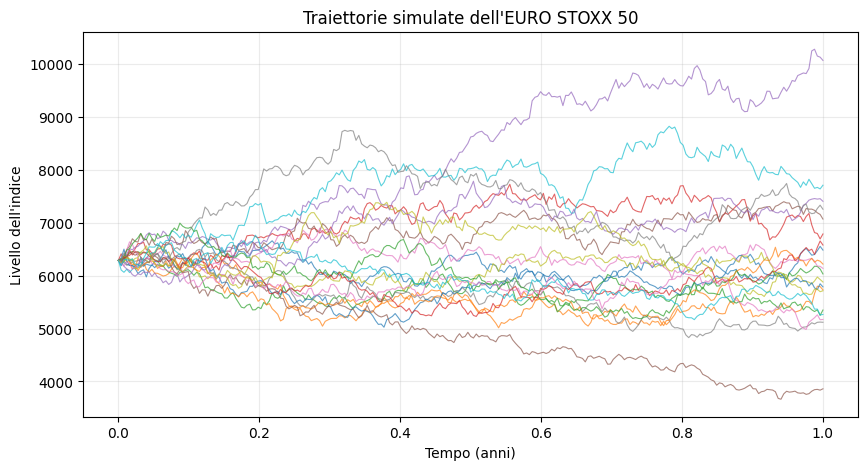

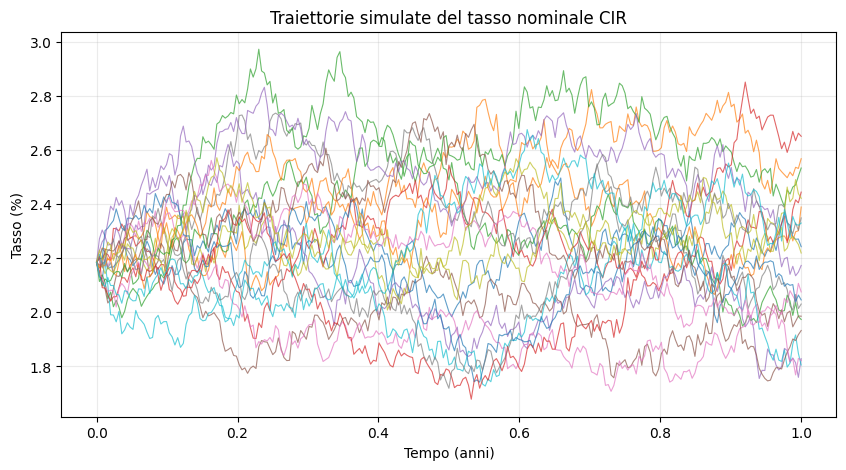

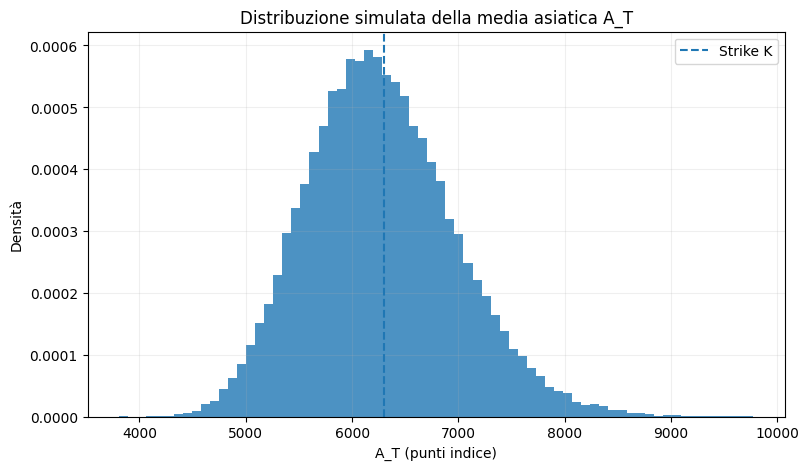

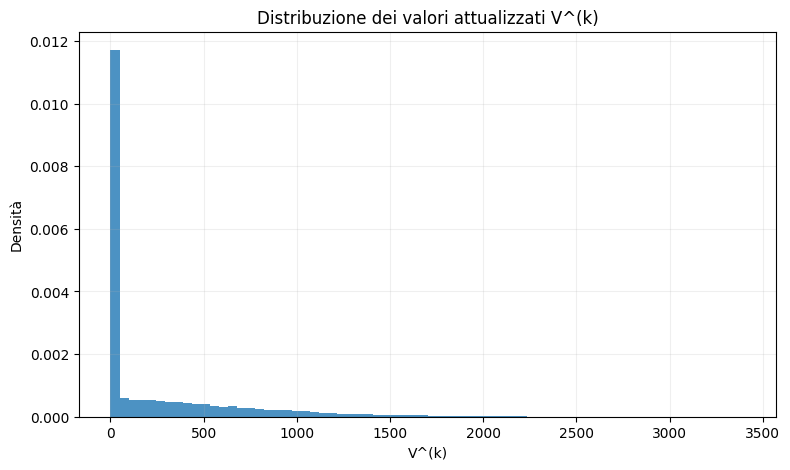

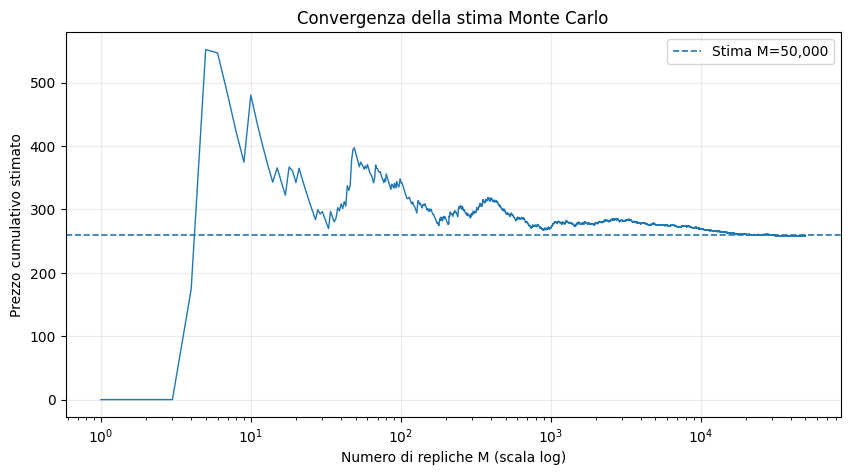

In [8]:
# Grafico 1 — Traiettorie simulate dell'indice
plt.figure(figsize=(10, 5))
for k in range(20):
    plt.plot(time_grid, S_paths[k, :], linewidth=0.8, alpha=0.7)
plt.title("Traiettorie simulate dell'EURO STOXX 50")
plt.xlabel("Tempo (anni)")
plt.ylabel("Livello dell'indice")
plt.grid(alpha=0.25)
plt.show()

# Grafico 2 — Traiettorie simulate del tasso nominale
plt.figure(figsize=(10, 5))
for k in range(20):
    plt.plot(time_grid, 100 * r_paths[k, :], linewidth=0.8, alpha=0.7)
plt.title("Traiettorie simulate del tasso nominale CIR")
plt.xlabel("Tempo (anni)")
plt.ylabel("Tasso (%)")
plt.grid(alpha=0.25)
plt.show()

# Grafico 3 — Distribuzione di A_T con strike
plt.figure(figsize=(9, 5))
plt.hist(A_T, bins=70, density=True, alpha=0.8)
plt.axvline(K, linestyle="--", linewidth=1.5, label="Strike K")
plt.title("Distribuzione simulata della media asiatica A_T")
plt.xlabel("A_T (punti indice)")
plt.ylabel("Densità")
plt.legend()
plt.grid(alpha=0.20)
plt.show()

# Grafico 4 — Distribuzione dei valori attualizzati
plt.figure(figsize=(9, 5))
plt.hist(V, bins=70, density=True, alpha=0.8)
plt.title("Distribuzione dei valori attualizzati V^(k)")
plt.xlabel("V^(k)")
plt.ylabel("Densità")
plt.grid(alpha=0.20)
plt.show()

# Grafico 5 — Convergenza Monte Carlo
cum_price = np.cumsum(V) / np.arange(1, M + 1)
plt.figure(figsize=(10, 5))
plt.plot(np.arange(1, M + 1), cum_price, linewidth=1.0)
plt.axhline(price, linestyle="--", linewidth=1.2, label=f"Stima M={M:,}")
plt.xscale("log")
plt.title("Convergenza della stima Monte Carlo")
plt.xlabel("Numero di repliche M (scala log)")
plt.ylabel("Prezzo cumulativo stimato")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

In [9]:
# Quadro finale dei controlli richiesti

controls = pd.DataFrame([
    ["1. Correlazione empirica shock", abs(corr_emp - rho) < 0.01,
     f"rho target={rho:.4f}; empirica={corr_emp:.4f}"],
    ["2. Positività di S_t", min_S > 0.0,
     f"min S_t={min_S:.6f}"],
    ["3. CIR: negativi rilevati senza flooring del nuovo valore", True,
     f"valori negativi rilevati={n_neg_r}; min r_t={min_r:.8f}"],
    ["4. Media asiatica entro min/max dei fixing", media_bounds_ok,
     "verifica replica per replica"],
    ["5. Payoff coerente", payoff_nonneg_ok and payoff_zero_ok,
     "H_T>=0 e H_T=0 quando A_T<=K"],
    ["6. Fattore di sconto positivo e stessa replica", discount_positive_ok,
     "D_T costruito dalla traiettoria r_t della replica"],
    ["7. Identità V=D*H", identity_ok,
     "verifica replica per replica"],
    ["8. SE compatibile con ordine M^(-1/2)", se_scaling_ok,
     f"CV di SE*sqrt(M)={se_scaling_cv:.4f}"],
    ["9. Stabilità rispetto a griglia più fine", abs(grid_diff) < 3 * paired_se + 0.10,
     f"diff={grid_diff:.6f}; SE diff accoppiata={paired_se:.6f}"],
    ["10. Riproducibilità", True,
     f"seed principale={SEED}; seed controllo griglia={SEED+1}"],
], columns=["Controllo", "Esito", "Evidenza"])

display(Markdown("### Quadro finale dei controlli"))
display(controls)

assert controls["Esito"].all(), "Almeno un controllo finale richiede revisione."

### Quadro finale dei controlli

,Controllo,Esito,Evidenza
0,1. Correlazione empirica shock,True,rho target=-0.2500; empirica=-0.2499
1,2. Positività di S_t,True,min S_t=2719.883695
2,3. CIR: negativi rilevati senza flooring del n...,True,valori negativi rilevati=0; min r_t=0.00915677
3,4. Media asiatica entro min/max dei fixing,True,verifica replica per replica
4,5. Payoff coerente,True,H_T>=0 e H_T=0 quando A_T<=K
5,6. Fattore di sconto positivo e stessa replica,True,D_T costruito dalla traiettoria r_t della replica
6,7. Identità V=D*H,True,verifica replica per replica
7,8. SE compatibile con ordine M^(-1/2),True,CV di SE*sqrt(M)=0.0176
8,9. Stabilità rispetto a griglia più fine,True,diff=-0.000911; SE diff accoppiata=0.000212
9,10. Riproducibilità,True,seed principale=12345; seed controllo griglia=...


# Interpretazione finanziaria conclusiva

La simulazione produce un valore del contratto coerente con il modello assegnato e con la misura di pricing \(\mathbb Q\). La media asiatica \(A_T\) è costruita sui dodici fixing contrattuali e non sul solo valore terminale \(S_T\): la path-dependence del payoff è quindi effettivamente preservata.

La frequenza \(\widehat{\mathbb Q}(A_T>K)\) descrive la probabilità dell'evento di esercizio **sotto la misura risk-neutral del modello simulato**. Non deve essere interpretata come previsione della frequenza fisica con cui l'indice supererà lo strike.

Il prezzo Monte Carlo è ottenuto attualizzando ogni payoff con il fattore di sconto costruito dalla traiettoria del tasso appartenente alla stessa replica. In questo modo la dipendenza fra sottostante e tasso entra sia nell'evoluzione di \(S_t\), attraverso il drift stocastico, sia nell'attualizzazione.

La diagnostica al crescere di \(M\) riguarda la precisione statistica della simulazione. Il confronto fra \(N=252\) e \(N=504\) riguarda invece la discretizzazione temporale. Le due fonti di approssimazione devono essere mantenute concettualmente distinte.

Il risultato ottenuto è un **valore di modello**, non una quotazione operativa osservabile sul mercato. I parametri \(q\) e \(\sigma_S\) sono proxy di mercato, mentre i parametri CIR e la correlazione sono assegnati a fini didattici; non è stata effettuata una calibrazione completa.

# Limiti del modello e riproducibilità

## Limiti

- dinamiche assegnate direttamente sotto \(\mathbb Q\), senza derivazione del cambio di misura;
- dividend yield, volatilità e correlazione assunti costanti;
- tasso nominale descritto da un solo fattore CIR;
- contratto Asian stilizzato e OTC;
- assenza di rischio di credito, liquidità, costi di transazione e fiscalità;
- somma di Riemann sinistra per l'integrale del tasso;
- schema discreto CIR che può produrre valori negativi, rilevati ma non forzati a zero;
- nessuna calibrazione completa a una superficie di volatilità o a una curva dei tassi.

## Riproducibilità

La simulazione principale usa il seed `12345`. Il controllo sulla discretizzazione usa un seed separato e documentato (`12346`) e driver browniani accoppiati fra griglia base e griglia più fine.

La riproducibilità riguarda l'esecuzione computazionale del notebook; non elimina l'errore Monte Carlo, l'errore di discretizzazione o l'errore di modello.